# Analiza danych medycznych – cukrzyca (Pima Indians Diabetes)

**Przedmiot:** Systemy Sztucznej Inteligencji – projekt
**Autor:** Dmytro Ilchenko

**Cel:** przewidywanie, czy pacjentka choruje na cukrzycę, na podstawie wyników badań
(klasyfikacja binarna), wraz z analizą eksploracyjną danych.

Notatnik przechodzi krok po kroku przez wszystkie etapy projektu:
1. Przygotowanie i czyszczenie danych
2. Analiza eksploracyjna (EDA)
3. Model ML i analiza wyników
4. Wnioski

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from config import FEATURES, TARGET, ZERO_AS_MISSING, FIGURES_DIR, ensure_dirs
import data_prep, eda, model

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
ensure_dirs()

## 1. Przygotowanie i czyszczenie danych

### 1.1 Wczytanie danych
Zbiór zawiera 768 pacjentek (kobiety pochodzenia Pima, wiek ≥ 21 lat), 8 cech medycznych
i zmienną docelową `Outcome` (1 – cukrzyca, 0 – brak).

In [2]:
raw = data_prep.load_data()
print("Rozmiar:", raw.shape)
raw.head()

Rozmiar: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


### 1.2 Kontrola jakości – ukryte braki danych
Metoda `isna()` nie pokazuje żadnych braków, ale w kilku kolumnach występują wartości **0**,
które są fizjologicznie niemożliwe (glukoza, ciśnienie, BMI, insulina, grubość fałdu skórnego).
To w rzeczywistości brakujące pomiary. Wyjątkiem jest `Pregnancies` – 0 ciąż jest wartością poprawną.

In [4]:
print("Duplikaty:", raw.duplicated().sum())
report = data_prep.quality_report(raw)
report

Duplikaty: 0


,typ,braki_NaN,liczba_zer,procent_zer
Pregnancies,int64,0,111,14.5
Glucose,int64,0,5,0.7
BloodPressure,int64,0,35,4.6
SkinThickness,int64,0,227,29.6
Insulin,int64,0,374,48.7
BMI,float64,0,11,1.4
DiabetesPedigreeFunction,float64,0,0,0.0
Age,int64,0,0,0.0
Outcome,int64,0,500,65.1


In [5]:
with_nan = data_prep.replace_zeros_with_nan(raw)
with_nan[ZERO_AS_MISSING].isna().sum().to_frame("braki po zamianie 0 → NaN")

,braki po zamianie 0 → NaN
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


### 1.3 Uzupełnienie braków – `fillna()`
Braki uzupełniamy **medianą** kolumny (odporna na wartości odstające, np. insulina > 800).
Ta wersja danych służy do EDA. W modelu uzupełnianie odbywa się wewnątrz `Pipeline`
(`SimpleImputer`) dopasowanym tylko na zbiorze treningowym, aby uniknąć wycieku danych testowych.

In [6]:
filled = data_prep.fill_missing(with_nan)
print("Braki po uzupełnieniu:", filled.isna().sum().sum())

Braki po uzupełnieniu: 0


### 1.4 Nowe cechy kategoryczne – `pd.cut()` i `merge()`
Dodajemy grupy wiekowe oraz kategorie BMI wg WHO. Opisy kategorii BMI znajdują się
w osobnej tabeli słownikowej, którą łączymy z danymi pacjentek za pomocą `merge()`.

In [7]:
data_prep.BMI_CATEGORIES

,BMI_code,BMI_category,BMI_range
0,0,Niedowaga,"< 18,5"
1,1,Norma,"18,5 – 24,9"
2,2,Nadwaga,"25,0 – 29,9"
3,3,Otyłość,"≥ 30,0"


In [8]:
clean = data_prep.add_categories(filled)
clean[["Age", "AgeGroup", "BMI", "BMI_code", "BMI_category", "BMI_range"]].head()

,Age,AgeGroup,BMI,BMI_code,BMI_category,BMI_range
0,50,41–50,33.6,3,Otyłość,"≥ 30,0"
1,31,31–40,26.6,2,Nadwaga,"25,0 – 29,9"
2,32,31–40,23.3,1,Norma,"18,5 – 24,9"
3,21,21–30,28.1,2,Nadwaga,"25,0 – 29,9"
4,33,31–40,43.1,3,Otyłość,"≥ 30,0"


## 2. Analiza eksploracyjna (EDA)

### 2.1 Statystyki opisowe – `describe()`

In [9]:
eda.descriptive_stats(clean)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,121.66,30.44,44.00,99.75,117.00,140.25,199.00
BloodPressure,768.0,72.39,12.10,24.00,64.00,72.00,80.00,122.00
SkinThickness,768.0,29.11,8.79,7.00,25.00,29.00,32.00,99.00
Insulin,768.0,140.67,86.38,14.00,121.50,125.00,127.25,846.00
BMI,768.0,32.46,6.88,18.20,27.50,32.30,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00


### 2.2 Rozkład klas – `value_counts()`
Zbiór jest umiarkowanie niezbalansowany (ok. 65% / 35%). Dlatego sama dokładność (accuracy)
nie wystarcza do oceny modelu – model zawsze odpowiadający „brak cukrzycy” miałby ~65% accuracy.

In [10]:
eda.class_balance(clean)

,liczba,procent
Diagnoza,,
Brak cukrzycy,500,65.1
Cukrzyca,268,34.9


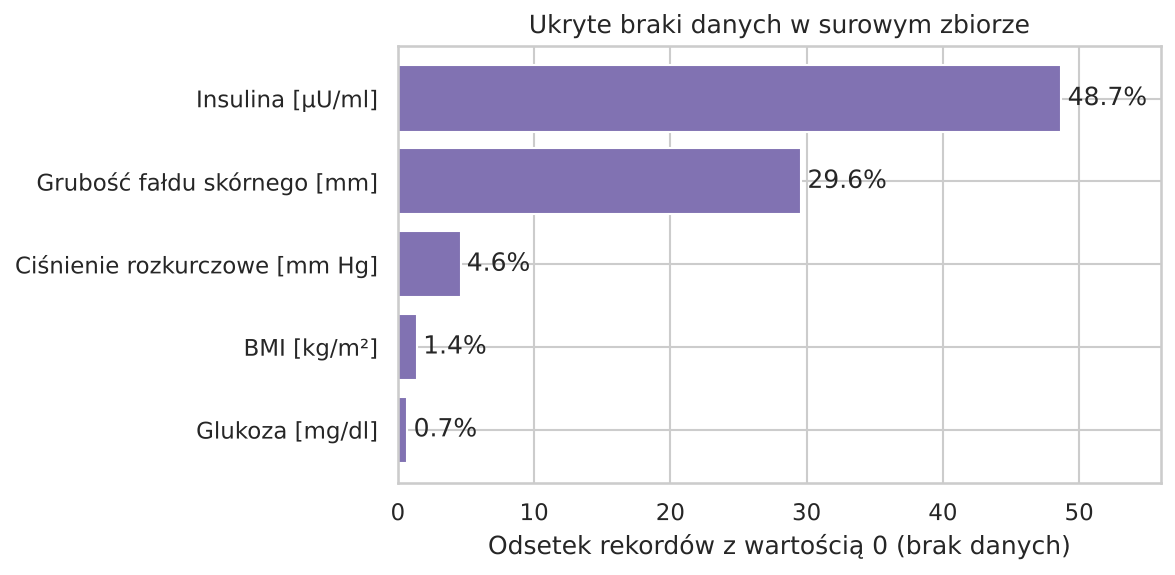

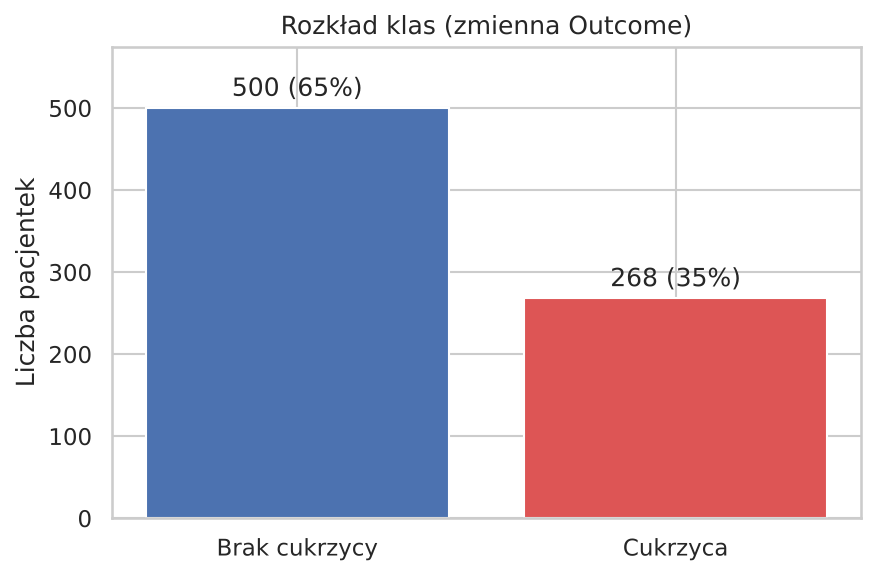

In [11]:
# Uruchamia wszystkie wykresy i zapisuje tabele do outputs/
tables = eda.run_eda(clean, report)
for f in ["01_braki_danych.png", "02_rozklad_klas.png"]:
    display(Image(FIGURES_DIR / f, width=600))

### 2.3 Rozkłady cech w podziale na diagnozę

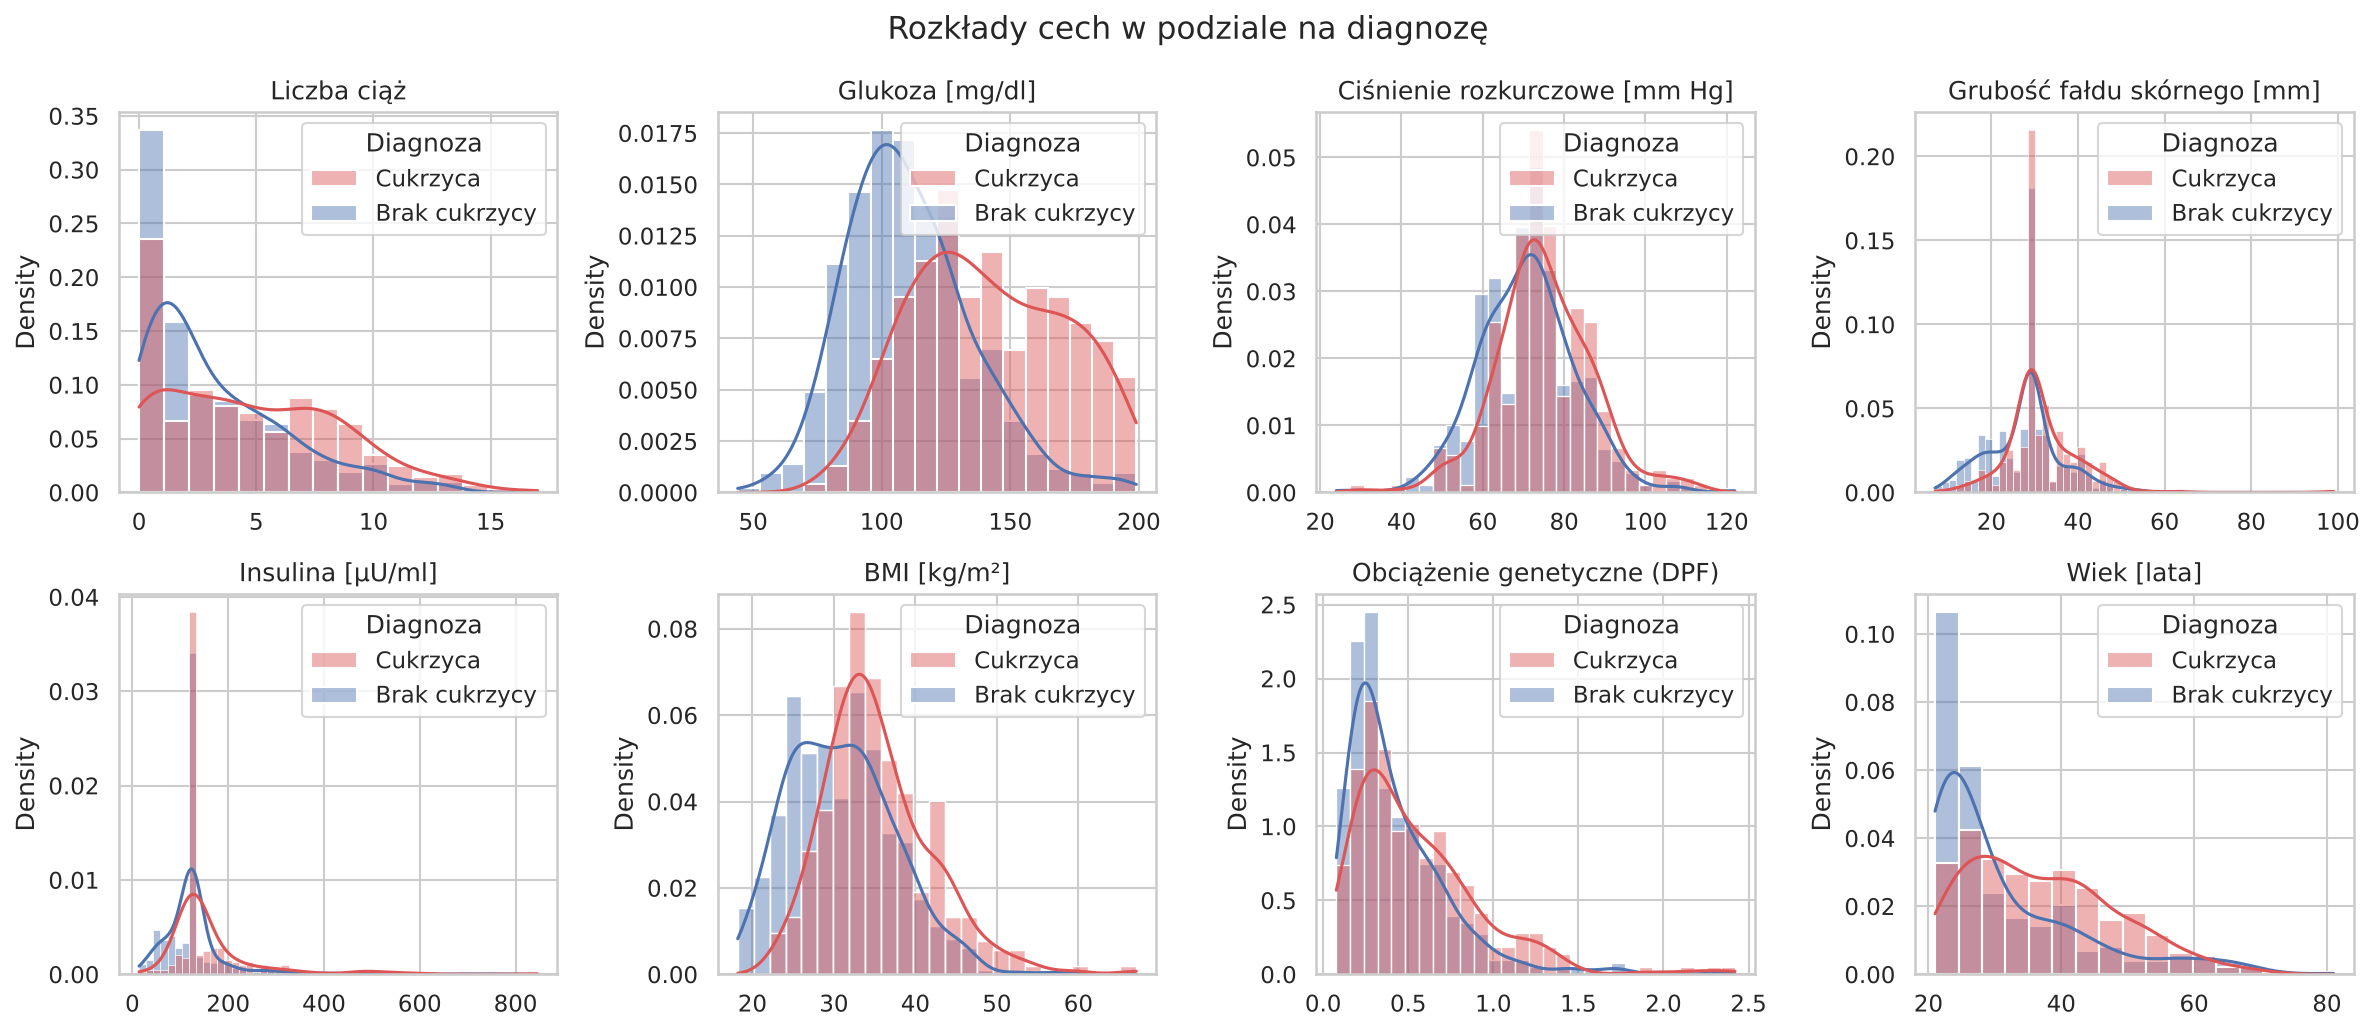

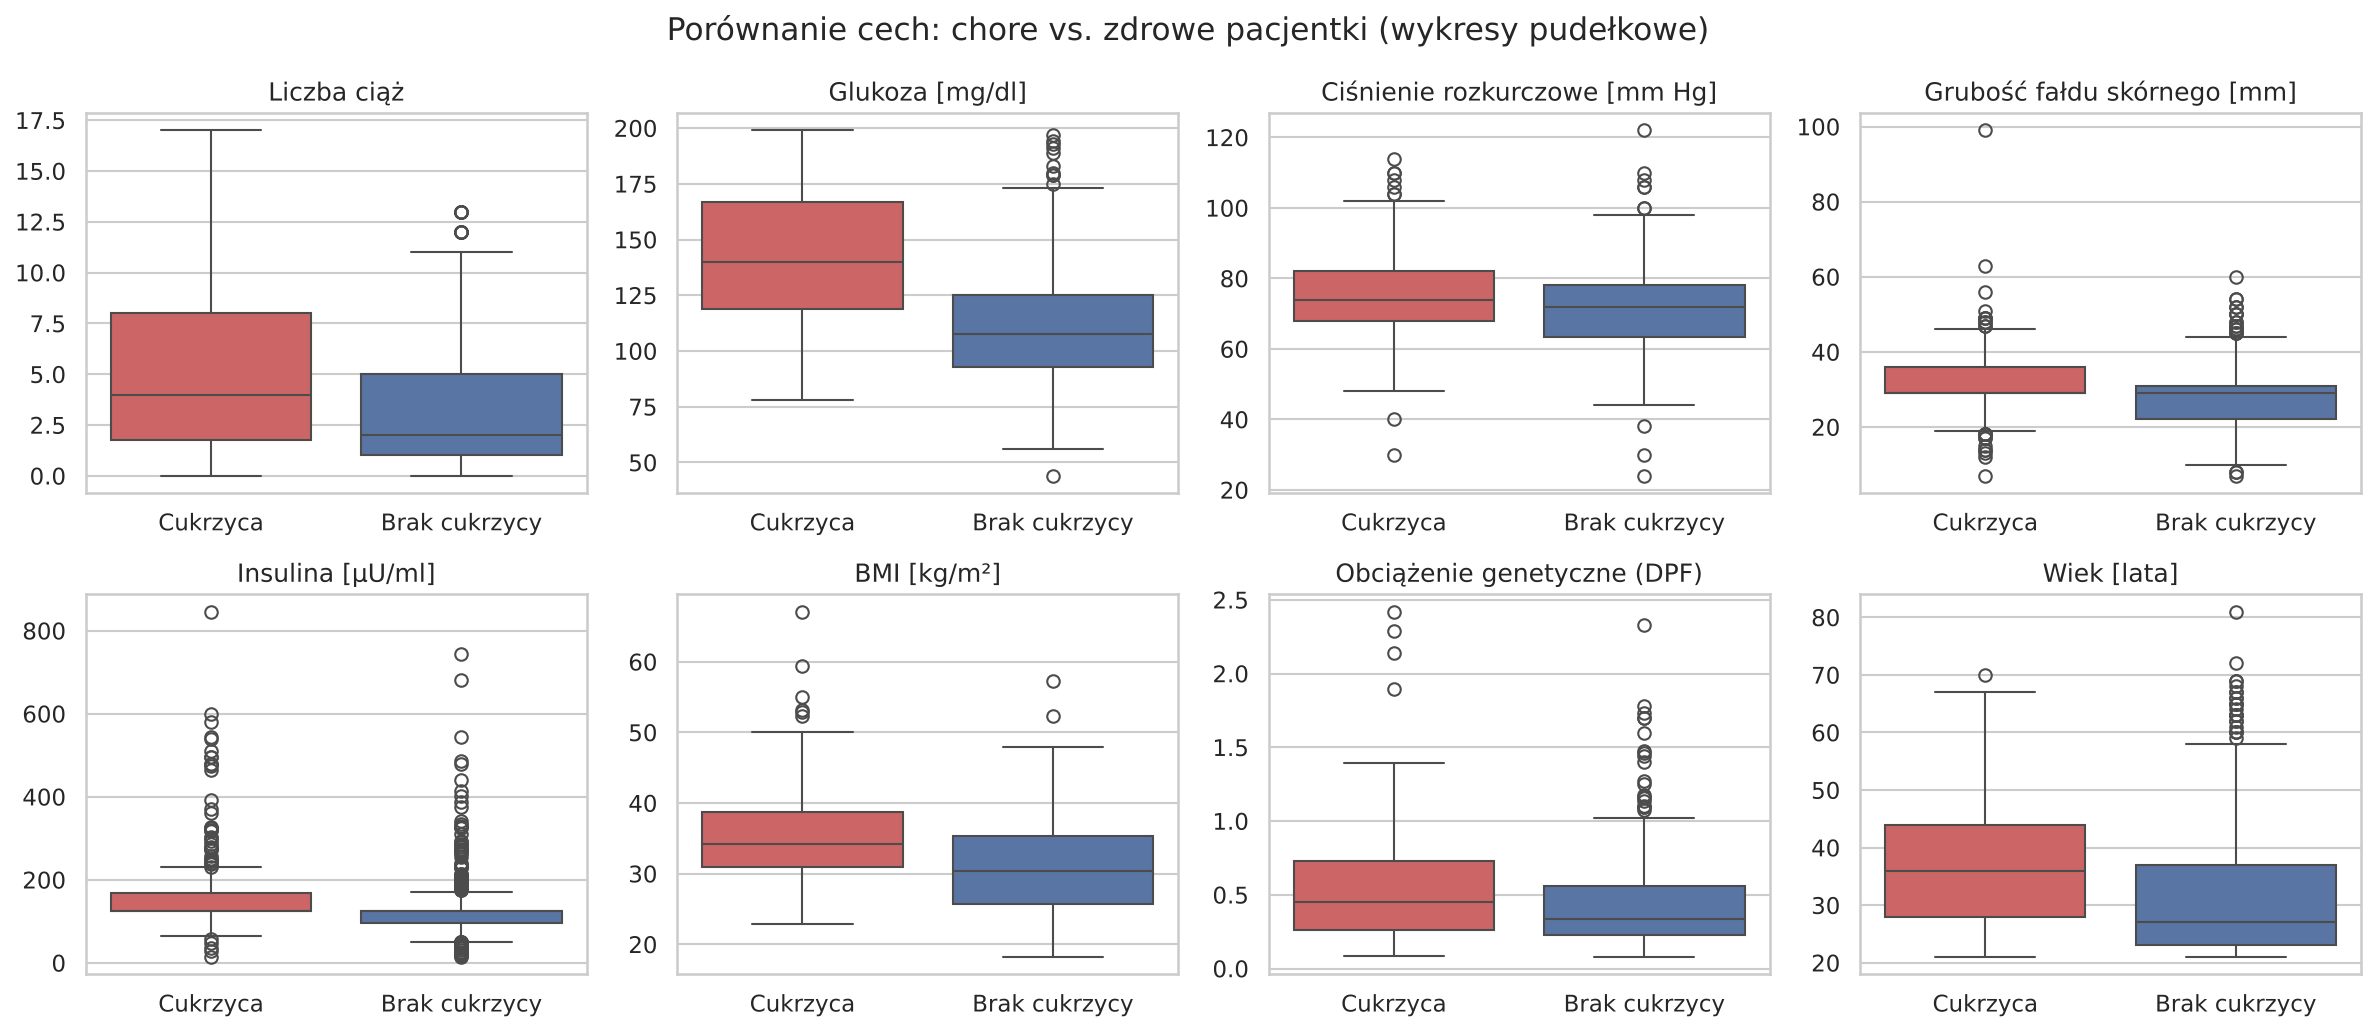

In [12]:
display(Image(FIGURES_DIR / "03_histogramy.png"))
display(Image(FIGURES_DIR / "04_boxploty.png"))

### 2.4 Średnie wartości cech wg diagnozy – `groupby()`

In [13]:
eda.stats_by_outcome(clean)

,Brak cukrzycy,Cukrzyca,Różnica
Pregnancies,3.30,4.87,1.57
Glucose,110.68,142.13,31.45
BloodPressure,70.92,75.12,4.20
SkinThickness,27.73,31.69,3.96
Insulin,127.79,164.70,36.91
BMI,30.89,35.38,4.49
DiabetesPedigreeFunction,0.43,0.55,0.12
Age,31.19,37.07,5.88


### 2.5 Korelacje – `corr()`

In [14]:
eda.correlations(clean).to_frame("korelacja z Outcome")

,korelacja z Outcome
Glucose,0.493
BMI,0.312
Age,0.238
Pregnancies,0.222
SkinThickness,0.215
Insulin,0.204
DiabetesPedigreeFunction,0.174
BloodPressure,0.166


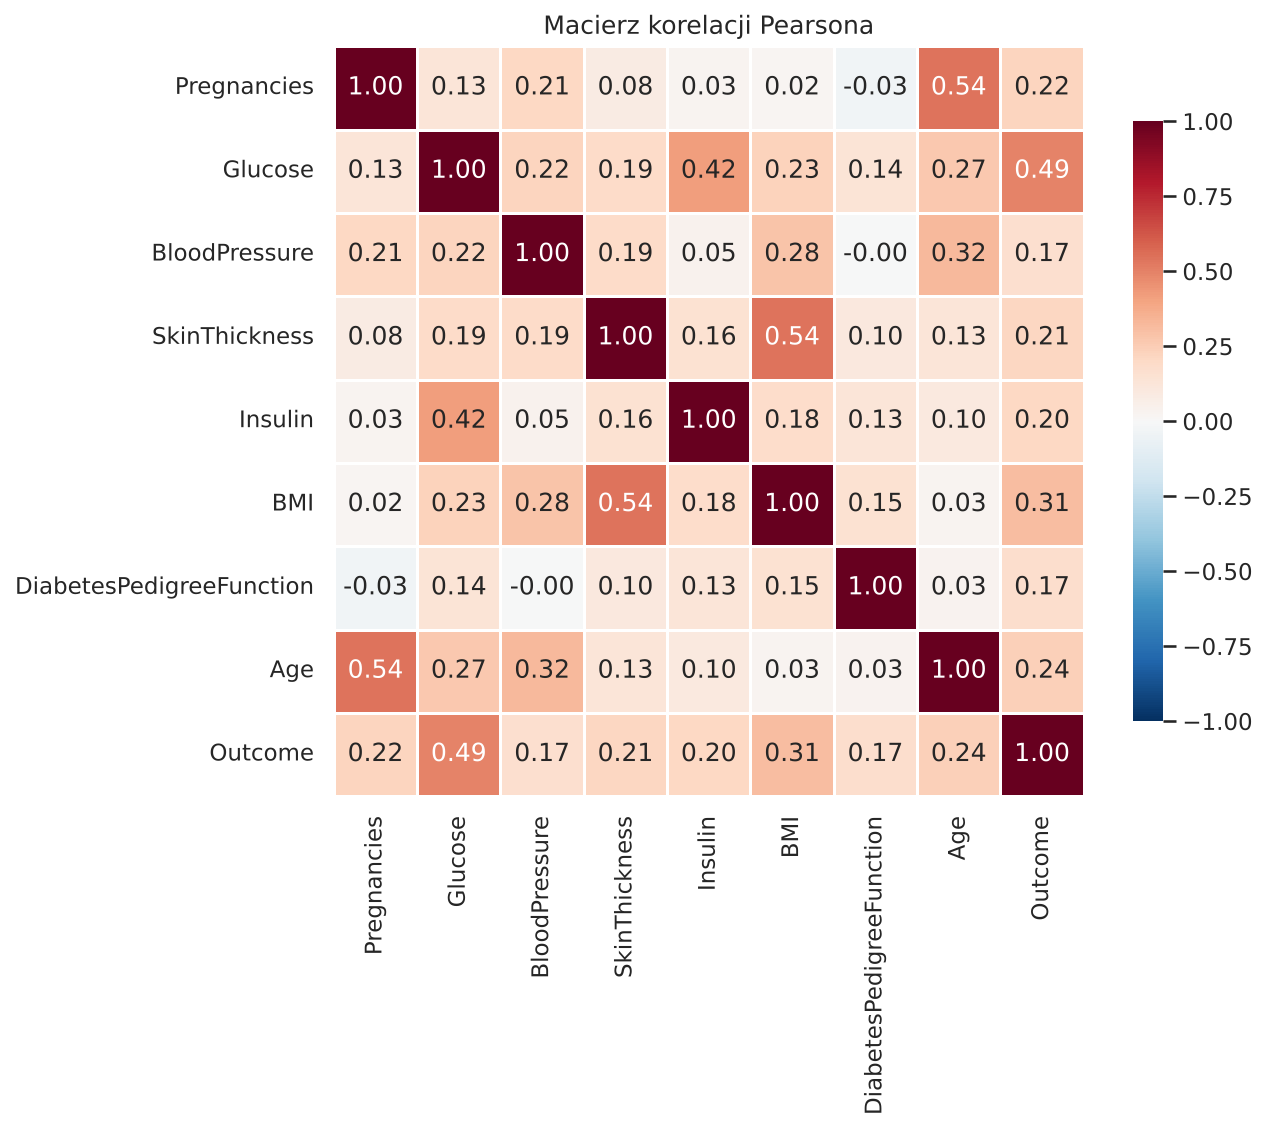

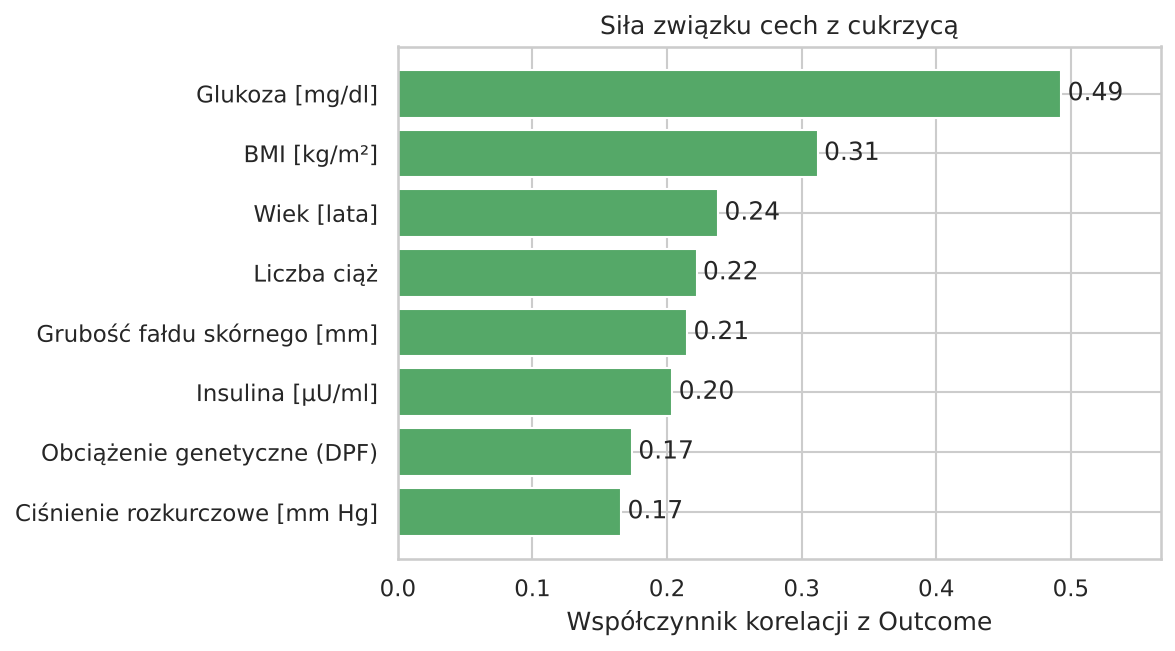

In [15]:
display(Image(FIGURES_DIR / "05_macierz_korelacji.png", width=650))
display(Image(FIGURES_DIR / "06_korelacja_z_outcome.png", width=650))

### 2.6 Odsetek chorych w grupach wiekowych i kategoriach BMI

In [16]:
display(eda.rate_by_group(clean, "AgeGroup"))
display(eda.rate_by_group(clean, "BMI_category"))

,liczba_pacjentek,liczba_chorych,odsetek_chorych
AgeGroup,,,
21–30,417,90,21.6
31–40,157,76,48.4
41–50,113,64,56.6
51–60,54,31,57.4
60+,27,7,25.9


,liczba_pacjentek,liczba_chorych,odsetek_chorych
BMI_category,,,
Niedowaga,4,0,0.0
Norma,102,7,6.9
Nadwaga,179,40,22.3
Otyłość,483,221,45.8


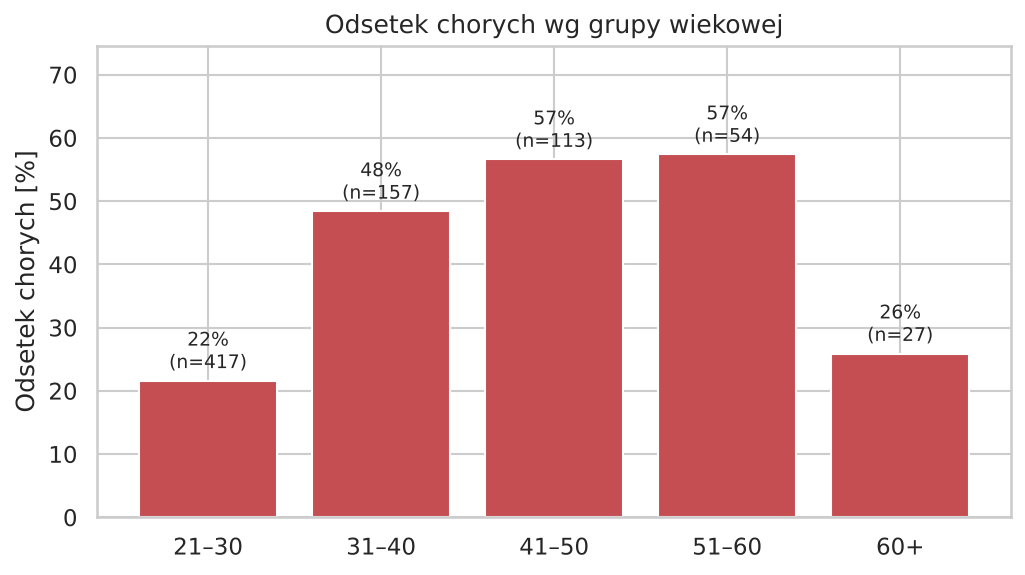

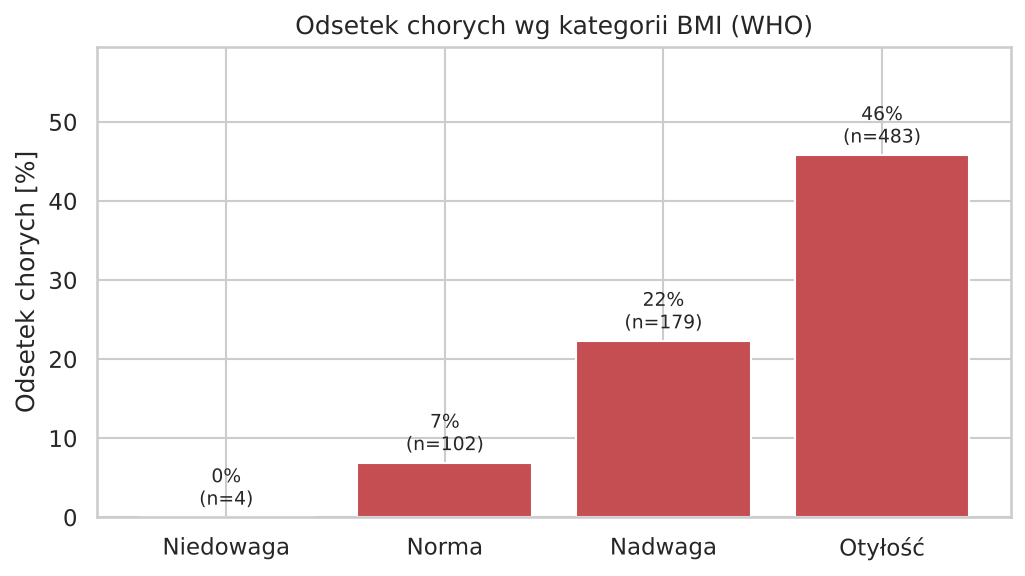

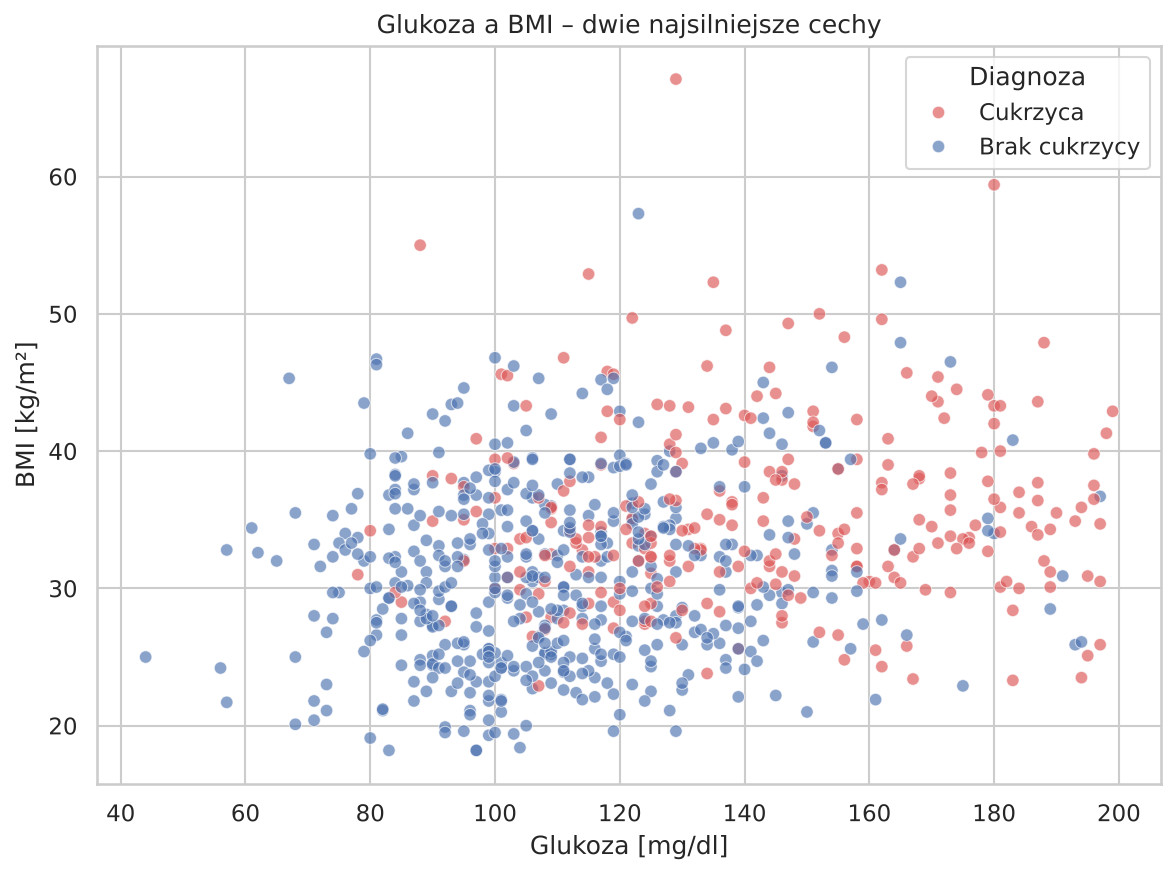

In [17]:
display(Image(FIGURES_DIR / "07_chorobowosc_wiek.png", width=600))
display(Image(FIGURES_DIR / "08_chorobowosc_bmi.png", width=600))
display(Image(FIGURES_DIR / "09_glukoza_vs_bmi.png", width=600))

## 3. Model ML i analiza wyników

Porównujemy trzy modele w jednakowym `Pipeline`
(`SimpleImputer(median)` → `StandardScaler` → klasyfikator):

* **Dummy** – zawsze przewiduje klasę większościową (punkt odniesienia),
* **Regresja logistyczna** – model główny, prosty i interpretowalny,
* **Las losowy** – model nieliniowy dla porównania.

Podział danych: 80% trening / 20% test, ze stratyfikacją.
Na zbiorze treningowym wykonujemy dodatkowo 5-krotną walidację krzyżową (ROC-AUC).

In [18]:
results = model.run_models(with_nan)
results["metrics"]

,cv_roc_auc_mean,cv_roc_auc_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,
Dummy (klasa większościowa),0.5,0.0,0.6494,0.0,0.0,0.0,0.5
Regresja logistyczna,0.8434,0.0185,0.7078,0.6,0.5,0.5455,0.813
Las losowy,0.8368,0.0209,0.7403,0.6667,0.5185,0.5833,0.8107


**Objaśnienie metryk:**
* *accuracy* – odsetek poprawnych odpowiedzi,
* *precision* – ile z osób oznaczonych jako chore jest rzeczywiście chorych,
* *recall* (czułość) – jaki odsetek chorych model wykrył,
* *F1* – średnia harmoniczna precision i recall,
* *ROC-AUC* – zdolność rozróżniania klas niezależnie od progu (0,5 = losowo, 1 = idealnie).

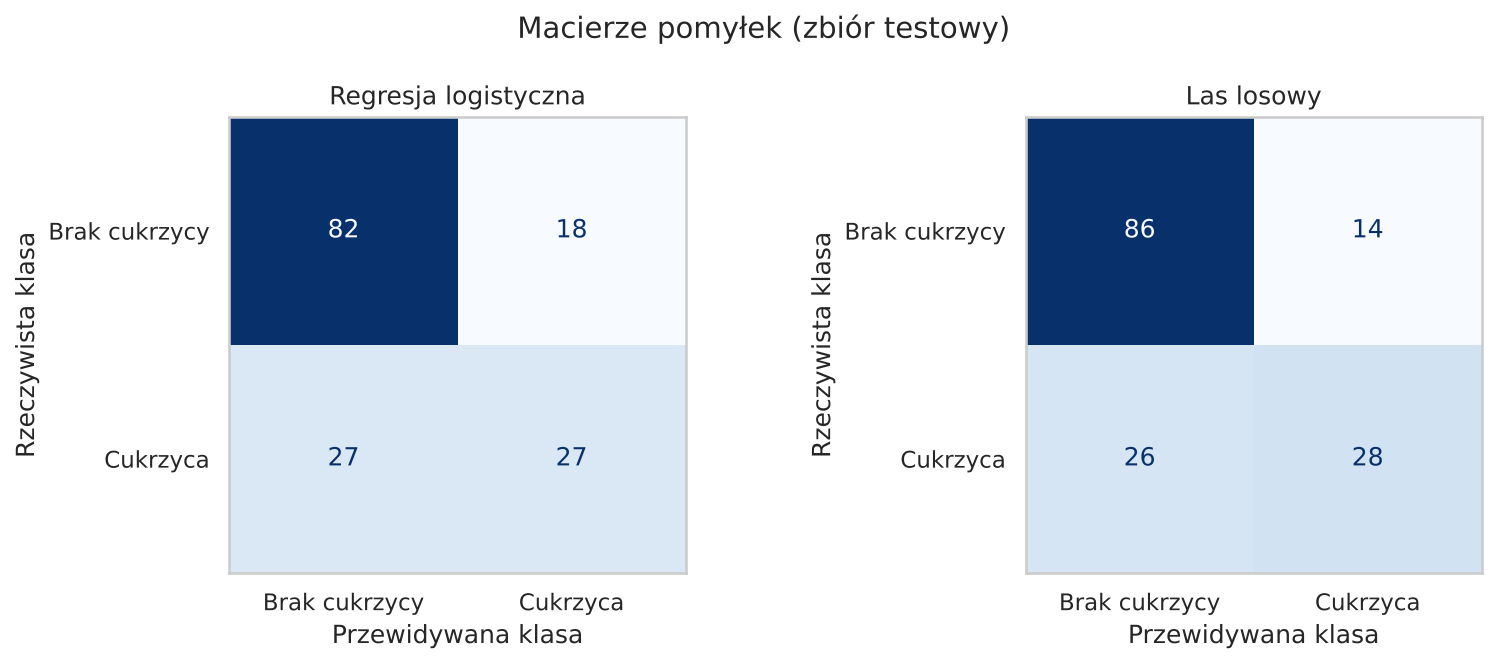

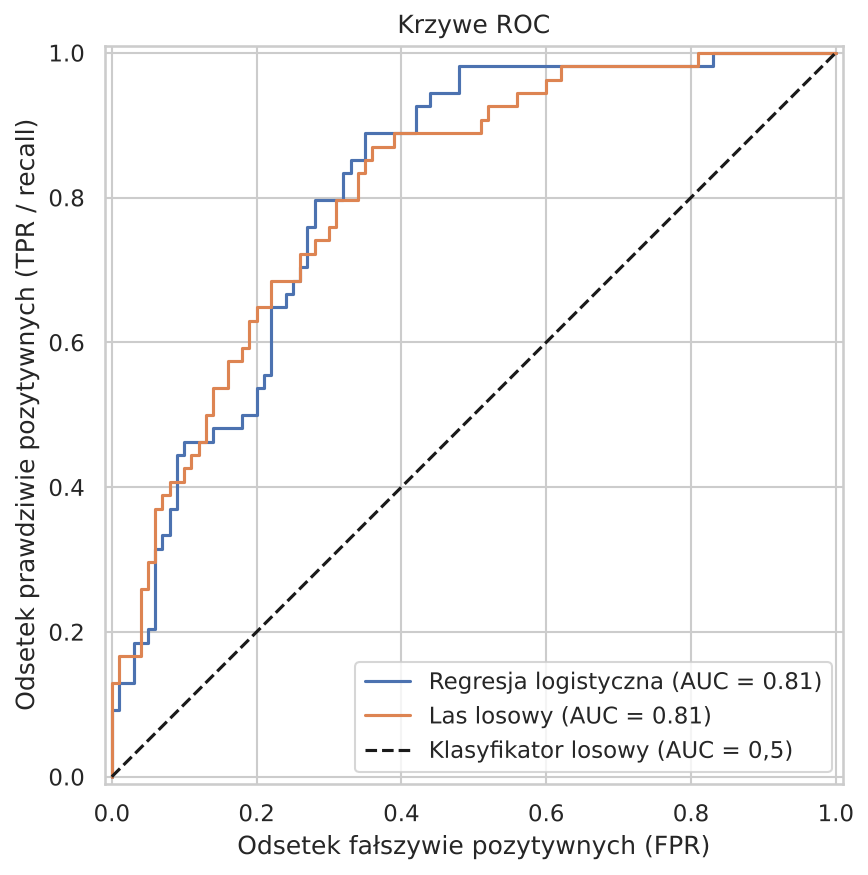

In [19]:
display(Image(FIGURES_DIR / "10_macierze_pomylek.png", width=750))
display(Image(FIGURES_DIR / "11_krzywe_roc.png", width=500))

### 3.1 Które cechy są najważniejsze?

,wspolczynnik_logreg,waznosc_rf
Glucose,1.1826,0.3736
BMI,0.6887,0.1689
Age,0.1478,0.1255
Insulin,-0.0661,0.0894
DiabetesPedigreeFunction,0.2333,0.0872
Pregnancies,0.3774,0.0577
SkinThickness,0.0283,0.0499
BloodPressure,-0.0441,0.0479


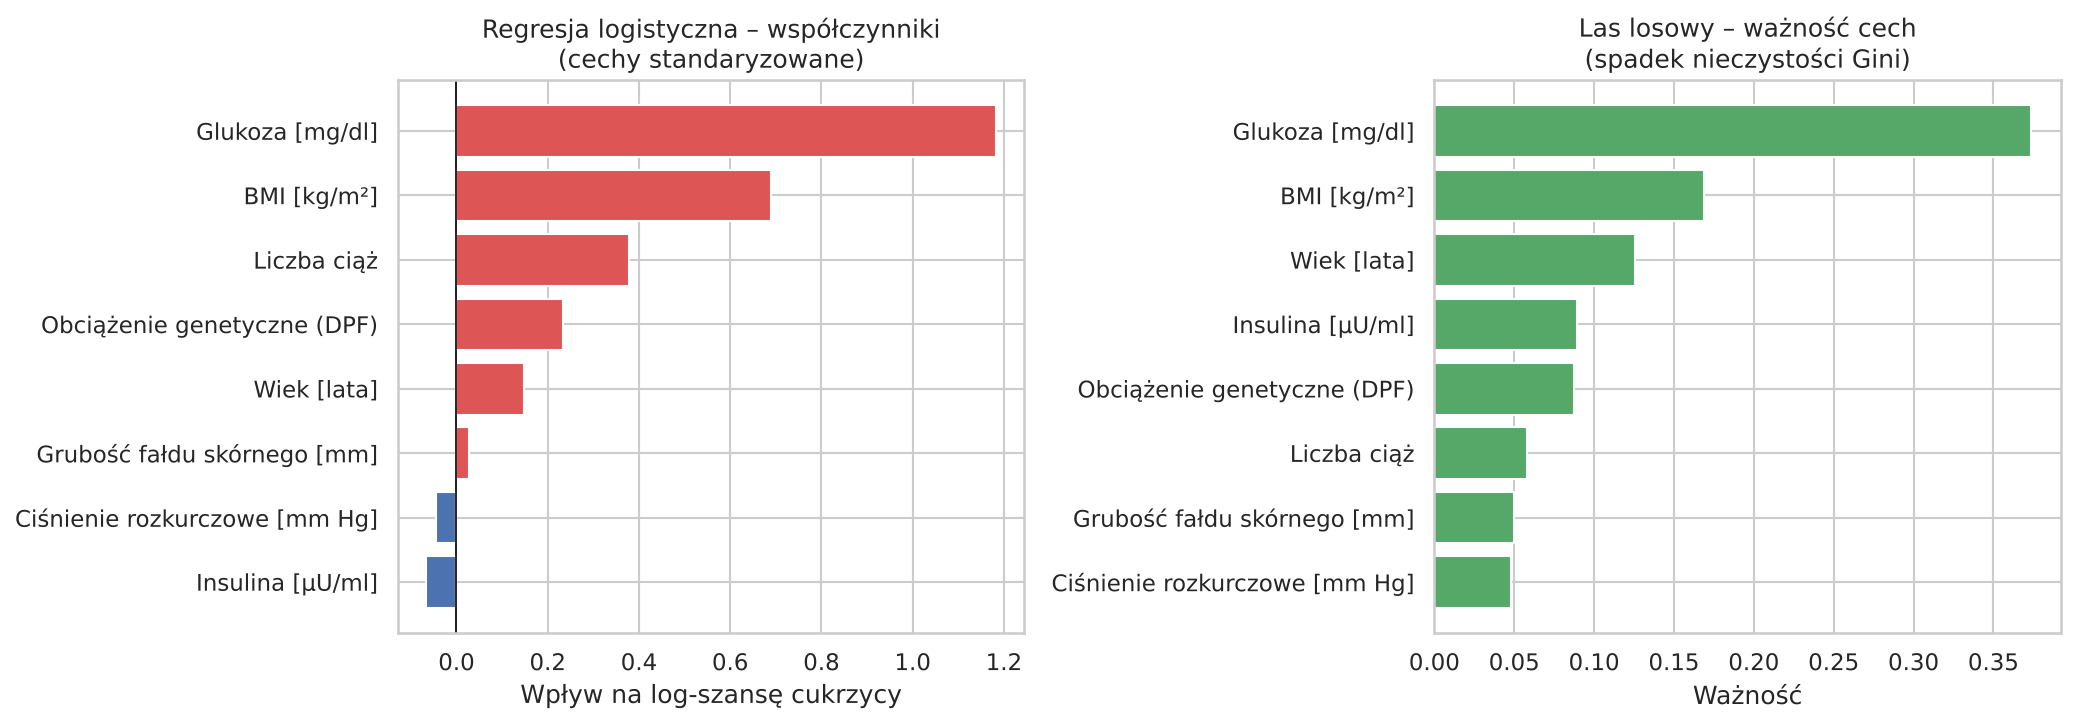

In [20]:
display(results["importance"].sort_values("waznosc_rf", ascending=False))
display(Image(FIGURES_DIR / "12_waznosc_cech.png"))

### 3.2 Dobór progu decyzyjnego
W badaniu przesiewowym przeoczenie chorej osoby (FN) jest groźniejsze niż fałszywy alarm (FP),
który zostanie zweryfikowany dodatkowym badaniem. Obniżenie progu z 0,5 do 0,3 zwiększa recall
kosztem precyzji.

,precision,recall,f1,wykryte_chore (TP),przeoczone_chore (FN),falszywe_alarmy (FP)
prog,,,,,,
0.3,0.597,0.796,0.683,43,11,29
0.4,0.614,0.648,0.631,35,19,22
0.5,0.600,0.500,0.545,27,27,18
0.6,0.641,0.463,0.538,25,29,14


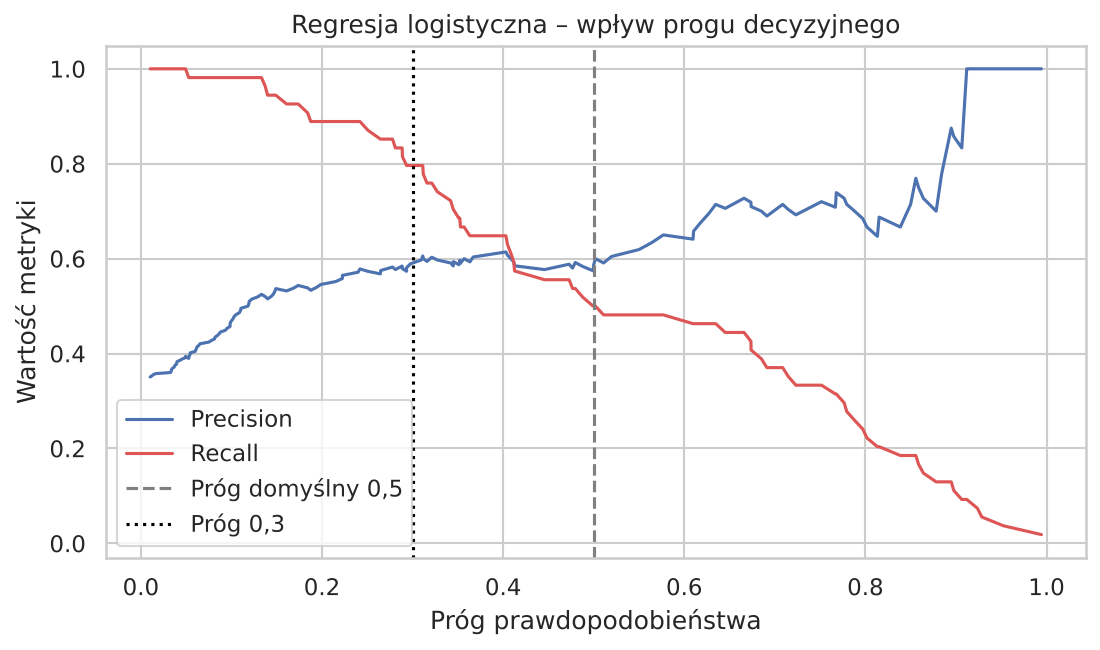

In [21]:
display(results["thresholds"])
display(Image(FIGURES_DIR / "13_analiza_progu.png", width=600))

## 4. Wnioski

1. **Jakość danych:** zbiór zawiera dużo ukrytych braków zapisanych jako 0
   (insulina ~49%, grubość fałdu skórnego ~30%). Bez ich obsługi statystyki i model byłyby zniekształcone.
2. **Najsilniejszy czynnik:** poziom **glukozy** (korelacja ≈ 0,49 z Outcome), następnie **BMI**,
   **wiek** i **liczba ciąż**. Potwierdzają to współczynniki regresji logistycznej i ważność cech w lesie losowym.
3. **Grupy ryzyka:** odsetek chorych rośnie z kategorią BMI (7% przy normie → 46% przy otyłości)
   i z wiekiem (22% w grupie 21–30 → ~57% w grupie 41–60).
4. **Modele:** regresja logistyczna i las losowy osiągają podobne ROC-AUC (~0,81 na teście,
   ~0,84 w walidacji krzyżowej), wyraźnie lepiej niż model bazowy (0,5). Prostszy model
   (regresja logistyczna) jest więc wystarczający i łatwiejszy do interpretacji.
5. **Próg decyzyjny:** przy progu 0,5 model wykrywa tylko połowę chorych. Obniżenie progu do 0,3
   podnosi recall do ok. 0,8, co jest korzystniejsze w zastosowaniu przesiewowym.

**Ograniczenia:** mały zbiór (768 rekordów), dane tylko jednej populacji (kobiety Pima),
duża liczba braków w kolumnie Insulin. Model ma charakter edukacyjny i nie zastępuje diagnozy lekarskiej.